In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score

# 퍼셉트론 

In [2]:
from sklearn.linear_model import Perceptron

붓꽃 데이터셋에서 꽃받침의 길이와 너비만 사용해 setosa vs others 이진 분류 문제로 변형

In [3]:
# Iris 데이터셋 로드
iris = load_iris()
X = iris.data[:, :2]  # 특성 2개 사용 (꽃받침 길이, 꽃받침 너비)
y = (iris.target != 0).astype(int) # 클래스 0과 클래스 1,2 구분을 위한 이진 분류 문제로 변환 (“setosa” vs “나머지”)

입력 데이터를 평균 0, 표준편차 1로 정규화한 뒤, 학습용과 테스트용으로 8:2 비율로 분할

In [4]:
# 데이터 정규화, 데이터 분할
# 평균이 0, 표준편차가 1이 되도록 데이터를 변환
# 모든 특성의 범위를 동등하게 맞춰주기 위함.
sc = StandardScaler() 
X_std = sc.fit_transform(X) 

# train : 학습용 데이터 / test : 시험용 데이터
# 학습용 데이터로 모델에 적합시키고, 그 모델의 성능을 시험용 데이터로 평가.
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=0.2, random_state=42)

In [5]:
# 퍼셉트론 모델 생성 및 훈련
# max_iter : 쵀대 반복 학습 횟수(epoch의 개수)
# eta0 : 학습률(learning rate)로, 가중치 업데이트의 크기를 결정
# random_state : 난수 생성기의 시드(seed)를 지정
perceptron = Perceptron(max_iter=10, eta0=0.1, random_state=42)
perceptron.fit(X_train, y_train)

Perceptron(eta0=0.1, max_iter=10, random_state=42)

In [6]:
# 테스트 데이터 예측
y_pred = perceptron.predict(X_test)

In [7]:
# 정확도 평가
accuracy_score(y_test, y_pred) # 단순한 이진 분류이기 때문에 자연스러운 결과

1.0

In [8]:
# 혼동 행렬
confusion_matrix(y_test, y_pred)

array([[10,  0],
       [ 0, 20]], dtype=int64)

이진 분류기의 결정 경계를 시각화하고, 실제 데이터 샘플과 함께 표시해 모델이 어떻게 데이터를 나누는지 눈으로 확인

In [9]:
# 결정 경계 시각화 함수
def plot_decision_regions(X, y, classifier, resolution=0.02):
    markers, colors = ('s', 'x'), ('red', 'blue')
    cmap = ListedColormap(colors)

    #특성 2개의 최소값, 최대값을 기준으로 그래프의 범위 지정.
    #각 끝에 1씩 여유 공간을 추가하여 시각화가 명확히 나타나도록 함
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    
    #위 범위에서 지정된 해상도(resolution)만큼 떨어진 격자점을 생성.
    #모델의 예측을 이 격자점들 위에서 수행하여 분류 경계 표시.
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution),
                           np.arange(x2_min, x2_max, resolution))

    # 각 격자점에서의 모델 예측
    Z = classifier.predict(np.array([xx1.ravel(), xx2.ravel()]).T).reshape(xx1.shape)
    # 결정 경계 시각화
    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)

    # 실제 데이터 포인트를 클래스별로 산점도로 표시
    # 
    for idx, cl in enumerate(np.unique(y)):
        plt.scatter(X[y == cl, 0], X[y == cl, 1],
                    alpha=0.8,c = colors[idx], edgecolor='k', marker='o', label=f'Class {cl}')

- 테스트 데이터(X_test, y_test)를 사용하여
- 퍼셉트론 모델(perceptron)의 결정 경계를 시각화

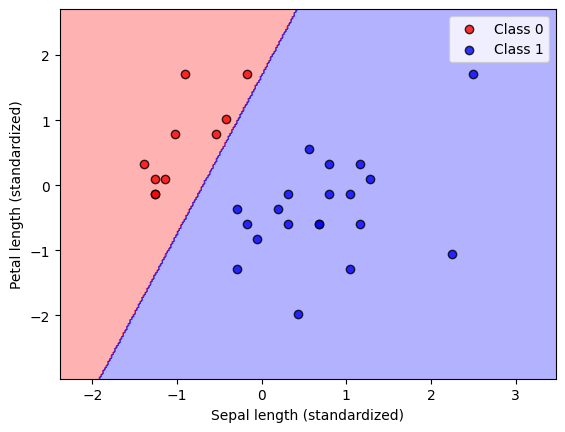

In [12]:
plot_decision_regions(X_test, y_test, perceptron)
# 정규화된 꽃받침 길이 / 너비
plt.xlabel('Sepal length (standardized)')
plt.ylabel('Petal length (standardized)')
plt.legend()
plt.show()

# 아달린 - Adaline (Adaptive Linear Neuron)
- iris 데이터 사용
- 퍼셉트론과 비슷하지만, 예측 시 이진 출력이 아닌 선형 출력값 사용
- 비용 함수로 Sum of Squared Errors (SSE) 사용
- 경사 하강법(Gradient Descent) 기반으로 가중치 학습

In [13]:
# 아달린 클래스 정의
class AdalineGD:
    def __init__(self, eta=0.01, epochs=50):
        self.eta = eta # 학습률
        self.epochs = epochs # 전체 데이터셋 학습 반복 횟수

    def fit(self, X, y):
        self.weights = np.zeros(1 + X.shape[1]) #가중치 0으로 초기화
        #weights[0]는 편향(bias), 나머지는 입력 특성에 대한 가중치
        self.costs = [] #학습 과정의 비용 저장 리스트

        for _ in range(self.epochs):
            output = self.predict_raw(X)
            errors = y - output #실제 레이블과 예측값의 차이 계산
            self.weights[1:] += self.eta * X.T.dot(errors) # 입력 특성 가중치 업데이트
            self.weights[0] += self.eta * errors.sum() # 편향 업데이트
            cost = (errors**2).sum() / 2.0 # 제곱 오차 비용(SSE)을 계산하여 저장
            self.costs.append(cost)
        return self

    def predict_raw(self, X): # 예측값(가중치와 입력의 선형 결합 결과) 계산
        return np.dot(X, self.weights[1:]) + self.weights[0]

    def predict(self, X): #선형 결합의 결과(predict_raw)를 기반으로 클래스 예측을 수행
        return np.where(self.predict_raw(X) >= 0, 0, 1) #0보다 크거나 같으면 클래스 0, 작으면 클래스 1로 분류

In [46]:
# 아달린 모델 생성 및 훈련
adaline = AdalineGD(eta=0.1, epochs=20)
adaline.fit(X_train, y_train)

In [47]:
# 테스트 데이터 예측
y_pred = adaline.predict(X_test)

In [48]:
#정확도 산출
accuracy = accuracy_score(y_test, y_pred)
print(f'아달린 모델의 정확도: {accuracy:.2f}')

아달린 모델의 정확도: 0.93


In [49]:
#혼동 행렬
confusion_matrix(y_test, y_pred)

array([[10,  0],
       [ 2, 18]], dtype=int64)

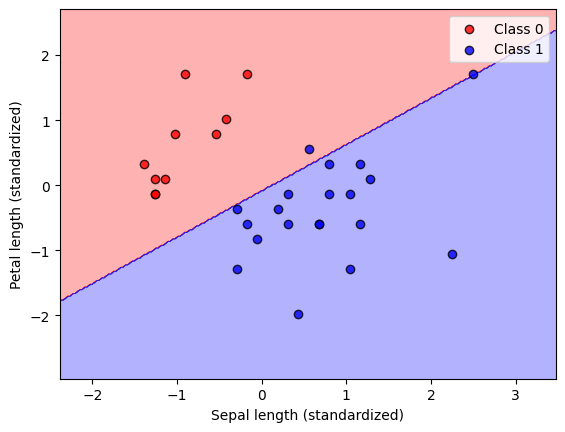

In [50]:
# 결정 경계 시각화
plot_decision_regions(X_test, y_test, adaline)
# 정규화된 꽃받침 길이 / 너비
plt.xlabel('Sepal length (standardized)')
plt.ylabel('Petal length (standardized)')
plt.legend()
plt.show()

epoch & eta 바꿔 보면서 모델을 학습시키면 결과가 달라짐.

**epoch 수를 늘리면 안 좋아지는 이유는 크게 두 가지**

1. 과적합: 데이터를 너무 외워버려 일반화 성능 하락.
2. 발산/진동: 학습률이 크면 최적점을 지나치며 성능 악화. (eta=0.1)

# 로지스틱 회귀모형
- iris 데이터 사용
- 분류 알고리즘
- 입력값을 선형 결합한 후 시그모이드(sigmoid) 함수를 적용하여, 확률 형태로 출력 → 0 또는 1 클래스로 분류

In [51]:
from sklearn.linear_model import LogisticRegression

In [62]:
# 로지스틱 회귀모형 학습
logreg = LogisticRegression() # # multi_class='auto', solver='lbfgs' 기본
logreg.fit(X_train, y_train)

LogisticRegression()

In [53]:
# 테스트 데이터 예측 및 정확도 평가
y_pred = logreg.predict(X_test)
print(f'로지스틱 회귀모형 정확도: {accuracy_score(y_test, y_pred):.2f}')

로지스틱 회귀모형 정확도: 1.00


In [54]:
#혼동 행렬
confusion_matrix(y_test, y_pred)

array([[10,  0],
       [ 0, 20]], dtype=int64)

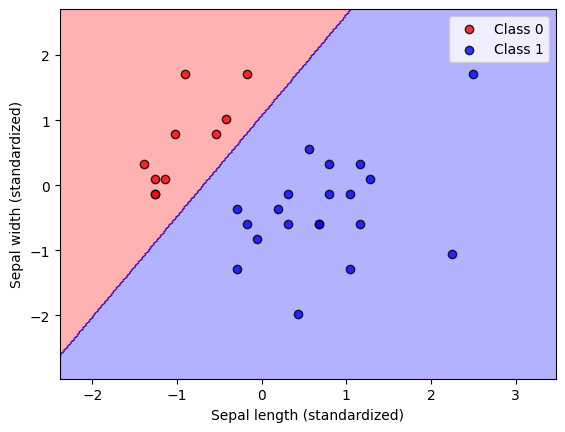

In [55]:
# 결정 경계선 시각화
plot_decision_regions(X_test, y_test, logreg)
plt.xlabel('Sepal length (standardized)')
plt.ylabel('Sepal width (standardized)')
plt.legend()
plt.show()

# 소프트맥스 회귀모형 (다중 분류)
iris 데이터

In [58]:
X = iris.data[:, :2]  # 특성 2개 사용 (꽃받침 길이, 꽃받침 너비)
y = iris.target  # 클래스 3개 모두 활용 (소프트맥스 다중 분류)

In [59]:
# 데이터 표준화 및 분할
sc = StandardScaler()
X_std = sc.fit_transform(X)
X_train, X_test, y_train, y_test = train_test_split(X_std, y, test_size=0.2, random_state=42)

In [90]:
softmax_reg = LogisticRegression(multi_class='multinomial', solver='lbfgs', max_iter=200)
softmax_reg.fit(X_train, y_train)

LogisticRegression(max_iter=200, multi_class='multinomial')

**multi_class =**
- 'ovr' (One-vs-Rest): 기본값, 각 클래스를 나머지 클래스와 구분하는 방식.
- 'multinomial': 소프트맥스 회귀(Softmax Regression) 방식.

**solver =** <- 최적화 알고리즘을 지정.
- 'liblinear': 작은 데이터셋, 이진 분류에 적합.
- 'lbfgs': 큰 데이터셋, 다중 클래스(multinomial)에 적합 (L2 정규화 지원).
- 'saga': 대규모 데이터, L1/L2 정규화 지원.

In [91]:
# 정확도 평가
y_pred = softmax_reg.predict(X_test)
print(f'소프트맥스 회귀모형 정확도: {accuracy_score(y_test, y_pred):.2f}')

소프트맥스 회귀모형 정확도: 0.90


In [92]:
confusion_matrix(y_test, y_pred)

array([[10,  0,  0],
       [ 0,  7,  2],
       [ 0,  1, 10]], dtype=int64)

In [93]:
# 결정 경계 시각화 함수 정의
def plot_decision_boundary(X, y, model, resolution=0.02):
    markers = ('s', 'x', 'o')
    colors = ('red', 'blue', 'green')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    x1_min, x1_max = X[:, 0].min()-1, X[:, 0].max()+1
    x2_min, x2_max = X[:, 1].min()-1, X[:, 1].max()+1

    xx1, xx2 = np.meshgrid(
        np.arange(x1_min, x1_max, resolution),
        np.arange(x2_min, x2_max, resolution))

    Z = model.predict(np.c_[xx1.ravel(), xx2.ravel()])
    Z = Z.reshape(xx1.shape)

    plt.contourf(xx1, xx2, Z, alpha=0.3, cmap=cmap)
    
    for idx, cls in enumerate(np.unique(y)):
        plt.scatter(X[y==cls, 0], X[y==cls, 1],
                    c=colors[idx], marker=markers[idx],
                    label=f'Class {cls}')

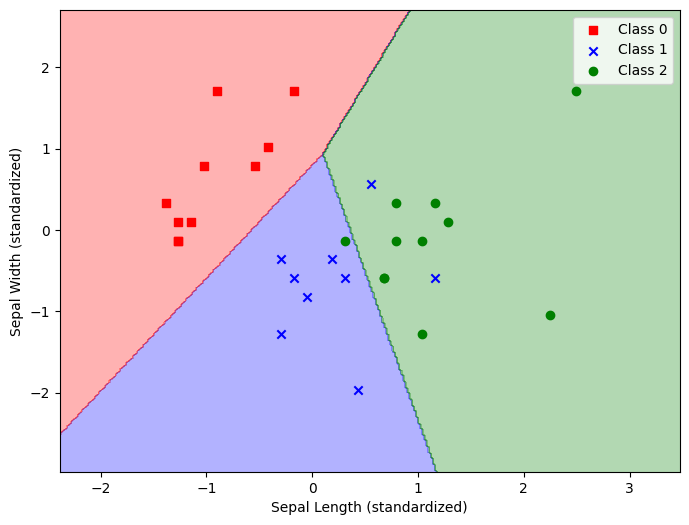

In [94]:
#결정 경계 시각화
plt.figure(figsize=(8,6))
plot_decision_boundary(X_test, y_test, softmax_reg)
plt.xlabel('Sepal Length (standardized)')
plt.ylabel('Sepal Width (standardized)')
plt.legend()
plt.show()

# 선형회귀
Seaborn에서 제공하는 내장 데이터셋 "mpg" (Miles Per Gallon) 사용

In [3]:
from sklearn.linear_model import LinearRegression

In [4]:
#auto mpg 데이터 가져오기
df = sns.load_dataset('mpg').dropna()
df

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,name
0,18.0,8,307.0,130.0,3504,12.0,70,usa,chevrolet chevelle malibu
1,15.0,8,350.0,165.0,3693,11.5,70,usa,buick skylark 320
2,18.0,8,318.0,150.0,3436,11.0,70,usa,plymouth satellite
3,16.0,8,304.0,150.0,3433,12.0,70,usa,amc rebel sst
4,17.0,8,302.0,140.0,3449,10.5,70,usa,ford torino
...,...,...,...,...,...,...,...,...,...
393,27.0,4,140.0,86.0,2790,15.6,82,usa,ford mustang gl
394,44.0,4,97.0,52.0,2130,24.6,82,europe,vw pickup
395,32.0,4,135.0,84.0,2295,11.6,82,usa,dodge rampage
396,28.0,4,120.0,79.0,2625,18.6,82,usa,ford ranger


In [6]:
# 독립 변수, 종속 변수 지정
X = df[['horsepower']]  # 특성(마력)
y = df['mpg']           # 타겟(연비)

# 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [7]:
# 선형 회귀 모델 생성 및 학습
model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [8]:
# 예측 수행
y_pred = model.predict(X_test)

In [9]:
# 모델 평가
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'MSE: {mse:.2f}, r2: {r2:.2f}')

MSE: 22.15, r2: 0.57


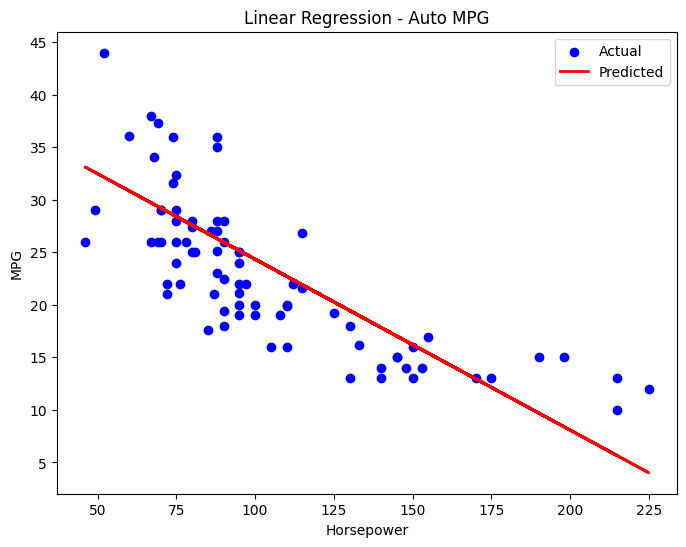

In [11]:
# 시각화
plt.figure(figsize=(8,6))
plt.scatter(X_test, y_test, color='blue', label='Actual')
plt.plot(X_test, y_pred, color='red', linewidth=2, label='Predicted')

plt.xlabel('Horsepower')
plt.ylabel('MPG')
plt.title('Linear Regression - Auto MPG')
plt.legend()
plt.show()

# 경사하강법

In [20]:
X = df[['horsepower']].values
y = df['mpg'].values.reshape(-1,1)

In [21]:
# 표준화
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

In [22]:
# 데이터셋 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

**확률적 경사하강법** (SGD: Stochastic Gradient Descent)

전체 데이터가 아니라 한 번에 하나의 데이터 샘플만을 이용해 가중치를 업데이트

속도가 매우 빠르나, 비용 함수가 심하게 진동할 수 있어 안정성이 떨어질 수 있음

In [23]:
# 하이퍼파라미터 설정
lr = 0.01
epochs = 50
m = len(X_train) # m = len(X_train) = 데이터 샘플 개수

In [24]:
# 가중치 초기화
w = np.zeros((X_train.shape[1], 1))
b = 0
costs_sgd = []

for epoch in range(epochs):
    for i in range(m):
        
        # 랜덤으로 선택된 하나의 데이터(Xi, yi)를 사용
        idx = np.random.randint(m)
        Xi = X_train[idx:idx+1]
        yi = y_train[idx:idx+1]

        y_pred = Xi @ w + b
        error = y_pred - yi

        # 기울기 계산
        dw = 2 * Xi.T @ error
        db = 2 * error.sum()

        # 가중치 업데이트
        w -= lr * dw
        b -= lr * db
    
    # 전체 데이터의 비용 기록
    # 에폭마다 전체 데이터를 대상으로 한 비용(cost)을 기록하여 학습 상황을 점검
    cost = np.mean((X_train @ w + b - y_train)**2)
    costs_sgd.append(cost)

In [25]:
# 평가
y_pred_test = X_test @ w + b
mse_sgd = mean_squared_error(y_test, y_pred_test)
print(f'SGD MSE: {mse_sgd:.4f}')

SGD MSE: 0.3482


**미니배치 경사하강법** (Mini-batch GD)

전체 데이터에서 일정 개수의 데이터(batch_size)를 미니배치로 추출해 가중치를 업데이트.

배치와 확률적 경사하강법의 장점을 섞은 방식으로 속도와 안정성을 동시에 확보할 수 있어 현실에서 가장 많이 사용

In [35]:
# 하이퍼파라미터 설정
lr = 0.01
epochs = 50
batch_size = 32
m = len(X_train) # m = len(X_train) = 데이터 샘플 개수

In [36]:
# 가중치 초기화
w = np.zeros((X_train.shape[1], 1))
b = 0
costs_minibatch = []

for epoch in range(epochs):
    #데이터를 매 epoch마다 랜덤하게 섞고, 
    #batch 크기만큼의 작은 그룹(미니배치)을 이용하여 가중치를 업데이트
    indices = np.random.permutation(m)
    X_train = X_train[indices]
    y_train = y_train[indices]

    for i in range(0, m, batch_size):
        Xi = X_train[i:i+batch_size]
        yi = y_train[i:i+batch_size]

        y_pred = Xi @ w + b
        error = y_pred - yi

        # 기울기 계산
        dw = (2/batch_size) * Xi.T @ error
        db = (2/batch_size) * error.sum()

        # 가중치 업데이트
        w -= lr * dw
        b -= lr * db

    # 비용 기록
    cost = np.mean((X_train @ w + b - y_train)**2)
    costs_minibatch.append(cost)

In [37]:
# 평가
y_pred_test = X_test @ w + b
mse_minibatch = mean_squared_error(y_test, y_pred_test)
print(f'Mini-batch GD MSE: {mse_minibatch:.4f}')

Mini-batch GD MSE: 0.3645


**Batch Gradient Descent** (배치 경사하강법)

모든 샘플을 사용해 기울기를 계산하기 때문에 매우 안정적이고, 수렴이 매끄럽게 이루어짐.

하지만 데이터셋이 크면 매번 전체를 계산해야 해서 계산 비용이 큼.

소규모 데이터셋에서는 적합하지만, 대규모 딥러닝 학습에는 잘 쓰이지 않음.

In [44]:
# 하이퍼파라미터 설정
lr = 0.01        # 학습률
epochs = 50      # 반복 횟수
m = len(X_train) # 학습 데이터 개수

# 가중치 초기화
w = np.zeros((X_train.shape[1], 1))
b = 0
costs_batch = []

# 배치 경사하강법 학습
for epoch in range(epochs):
    # 예측값
    y_pred = X_train @ w + b
    error = y_pred - y_train

    # 기울기 계산 (전체 데이터 사용)
    dw = (2/m) * (X_train.T @ error)
    db = (2/m) * error.sum()

    # 가중치 업데이트
    w -= lr * dw
    b -= lr * db

    # 비용 계산 후 기록
    cost = np.mean((X_train @ w + b - y_train) ** 2)
    costs_batch.append(cost)

In [49]:
# 테스트 데이터 예측 및 성능 평가
y_pred_test = X_test @ w + b
mse_batch = mean_squared_error(y_test, y_pred_test)
print(f'Batch GD MSE: {mse_batch:.4f}')

Batch GD MSE: 0.3852


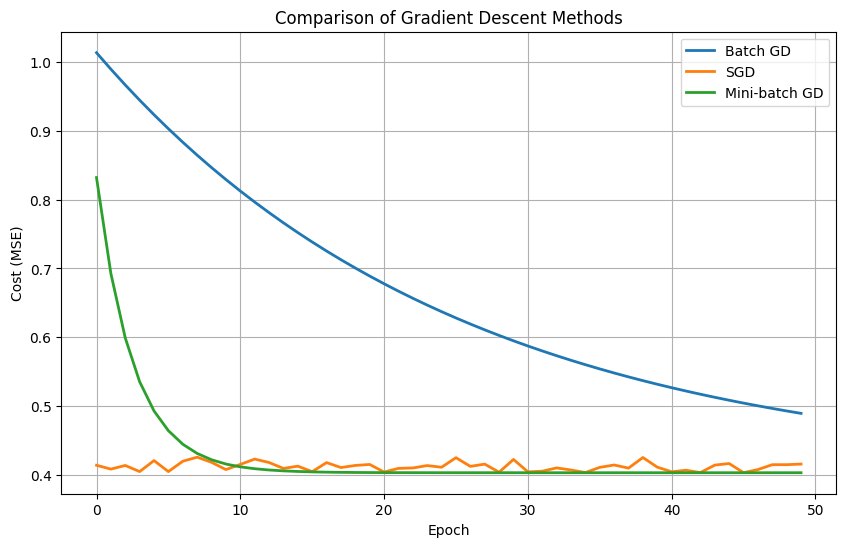

In [46]:
plt.figure(figsize=(10,6))
plt.plot(costs_batch, label='Batch GD', linewidth=2)
plt.plot(costs_sgd, label='SGD', linewidth=2)
plt.plot(costs_minibatch, label='Mini-batch GD', linewidth=2)

plt.xlabel('Epoch')
plt.ylabel('Cost (MSE)')
plt.title('Comparison of Gradient Descent Methods')
plt.legend()
plt.grid(True)
plt.show()


# Mini-batch GD 다중 회귀 코드

In [55]:
import numpy as np
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

# ---------------------------------
# 1. 데이터 준비
# ---------------------------------
# origin을 숫자형으로 변환 (one-hot encoding)
df = pd.get_dummies(df, columns=['origin'], drop_first=True)

# X: 모든 수치형 변수 사용
X = df[['cylinders', 'displacement', 'horsepower', 'weight',
        'acceleration', 'model_year', 'origin_japan', 'origin_usa']].values
y = df['mpg'].values.reshape(-1, 1)


# 표준화
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X = scaler_X.fit_transform(X)
y = scaler_y.fit_transform(y)

# 학습/테스트 분할
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# ---------------------------------
# 2. Mini-batch 경사하강법
# ---------------------------------
lr = 0.01
epochs = 100
batch_size = 32
m = len(X_train)

w = np.zeros((X_train.shape[1], 1))  # (특성 수, 1)
b = 0
costs_minibatch = []

for epoch in range(epochs):
    # 데이터 섞기
    indices = np.random.permutation(m)
    X_train = X_train[indices]
    y_train = y_train[indices]

    # 미니배치 학습
    for i in range(0, m, batch_size):
        Xi = X_train[i:i+batch_size]
        yi = y_train[i:i+batch_size]

        y_pred = Xi @ w + b
        error = y_pred - yi

        dw = (2 / batch_size) * Xi.T @ error
        db = (2 / batch_size) * error.sum()

        w -= lr * dw
        b -= lr * db

    # 비용 기록
    cost = np.mean((X_train @ w + b - y_train)**2)
    costs_minibatch.append(cost)

print("Mini-batch GD 학습 완료!")

# ---------------------------------
# 3. 성능 평가
# ---------------------------------
y_pred_test = X_test @ w + b
mse_minibatch = mean_squared_error(y_test, y_pred_test)
r2_minibatch = r2_score(y_test, y_pred_test)

print(f"Mini-batch GD (모든 변수) -> MSE: {mse_minibatch:.4f}, R²: {r2_minibatch:.4f}")


Mini-batch GD 학습 완료!
Mini-batch GD (모든 변수) -> MSE: 0.1841, R²: 0.7808
